In [32]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.cluster import AgglomerativeClustering
from matplotlib import cm
import sys
from pathlib import Path

In [33]:
# Add the project root (parent of notebooks/) to sys.path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.pipeline import NYCTaxiPipeline

pipe = NYCTaxiPipeline()
train_df, test_df = pipe.split()

train_ready = pipe.fit_transform(train_df)
test_ready = pipe.transform(test_df)

In [34]:
# 1. Build the 263 Zones x 24 Hours Demand Profile Matrix
# We aggregate the training data to find the average trip count per zone for each hour of the day (0 to 23).
profile_df = (
    train_df.groupby(["zone_id", "hour"])["trip_count"]
    .mean()
    .unstack(level="hour")  # Shape: (263 zones, 24 hours)
    .fillna(0)
)

# Extract feature matrix X and zone IDs
zone_ids = profile_df.index.values
X_profiles = profile_df.values

# 2. Standardize the Demand Profiles
# This ensures that high-volume zones (like Midtown) and low-volume zones 
# are compared based on their temporal *shape* rather than absolute magnitude.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_profiles)

In [35]:
# 1. Fit Agglomerative Hierarchical Clustering (matching your optimal_k = 6)
optimal_k = 6
current_random_state = 42  # For tracking / consistency

# Ward linkage minimizes the variance within each cluster, similar to K-Means' objective
hierarchical = AgglomerativeClustering(
    n_clusters=optimal_k, linkage="ward", metric="euclidean"
)
hierarchical_labels = hierarchical.fit_predict(X_scaled)

# 2. Compute Silhouette Score
hierarchical_silhouette_avg = silhouette_score(X_scaled, hierarchical_labels)
print(
    f"✨ Hierarchical Clustering (Ward) Silhouette Score (k = {optimal_k}):"
    f" {hierarchical_silhouette_avg:.4f}"
)

# Assign back to a new profile dataframe for comparison
hier_profile_df = profile_df.copy()
hier_profile_df["cluster"] = hierarchical_labels

✨ Hierarchical Clustering (Ward) Silhouette Score (k = 6): 0.7993


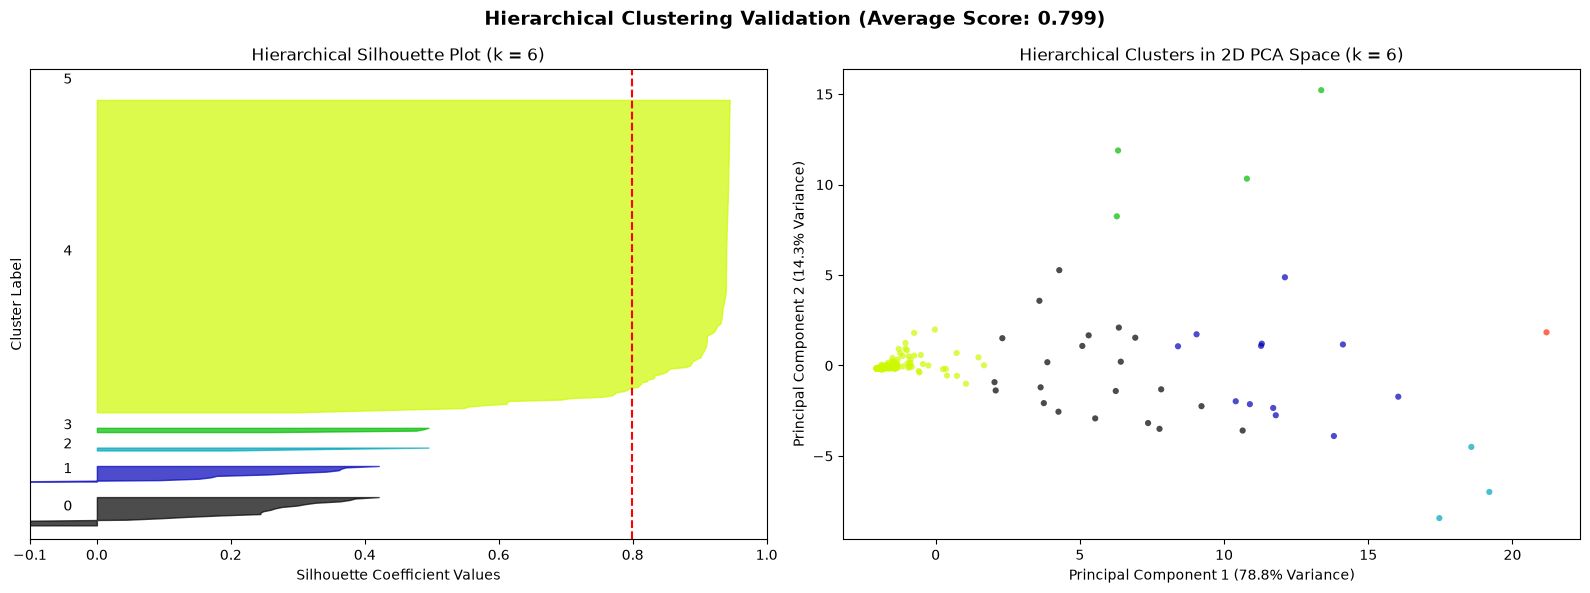

In [36]:
# 3. Generate Silhouette Diagram & PCA Scatter Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Silhouette Plot (Left Subplot)
ax1.set_xlim([-0.1, 1.0])
ax1.set_ylim([0, len(X_scaled) + (optimal_k + 1) * 10])

sample_silhouette_values = silhouette_samples(X_scaled, hierarchical_labels)

y_lower = 10
for i in range(optimal_k):
  ith_cluster_silhouette_values = sample_silhouette_values[
      hierarchical_labels == i
  ]
  ith_cluster_silhouette_values.sort()

  size_cluster_i = ith_cluster_silhouette_values.shape[0]
  y_upper = y_lower + size_cluster_i

  color = cm.nipy_spectral(float(i) / optimal_k)
  ax1.fill_betweenx(
      np.arange(y_lower, y_upper),
      0,
      ith_cluster_silhouette_values,
      facecolor=color,
      edgecolor=color,
      alpha=0.7,
  )
  ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
  y_lower = y_upper + 10

ax1.set_title(f"Hierarchical Silhouette Plot (k = {optimal_k})")
ax1.set_xlabel("Silhouette Coefficient Values")
ax1.set_ylabel("Cluster Label")
ax1.axvline(x=hierarchical_silhouette_avg, color="red", linestyle="--")
ax1.set_yticks([])
ax1.set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1.0])

# PCA Scatter Plot (Right Subplot)
pca = PCA(n_components=2, random_state=current_random_state)
X_pca = pca.fit_transform(X_scaled)
colors = cm.nipy_spectral(hierarchical_labels.astype(float) / optimal_k)

ax2.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    marker=".",
    s=80,
    lw=0,
    alpha=0.7,
    c=colors,
    edgecolor="k",
)
ax2.set_title(f"Hierarchical Clusters in 2D PCA Space (k = {optimal_k})")
ax2.set_xlabel(
    f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)"
)
ax2.set_ylabel(
    f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)"
)

plt.suptitle(
    f"Hierarchical Clustering Validation (Average Score:"
    f" {hierarchical_silhouette_avg:.3f})",
    fontsize=14,
    fontweight="bold",
)
plt.tight_layout()

# Save plot for your comparison log
plt.savefig(
    f"../reports/figures/hierarchical_silhouette_k{optimal_k}_seed_{current_random_state}.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

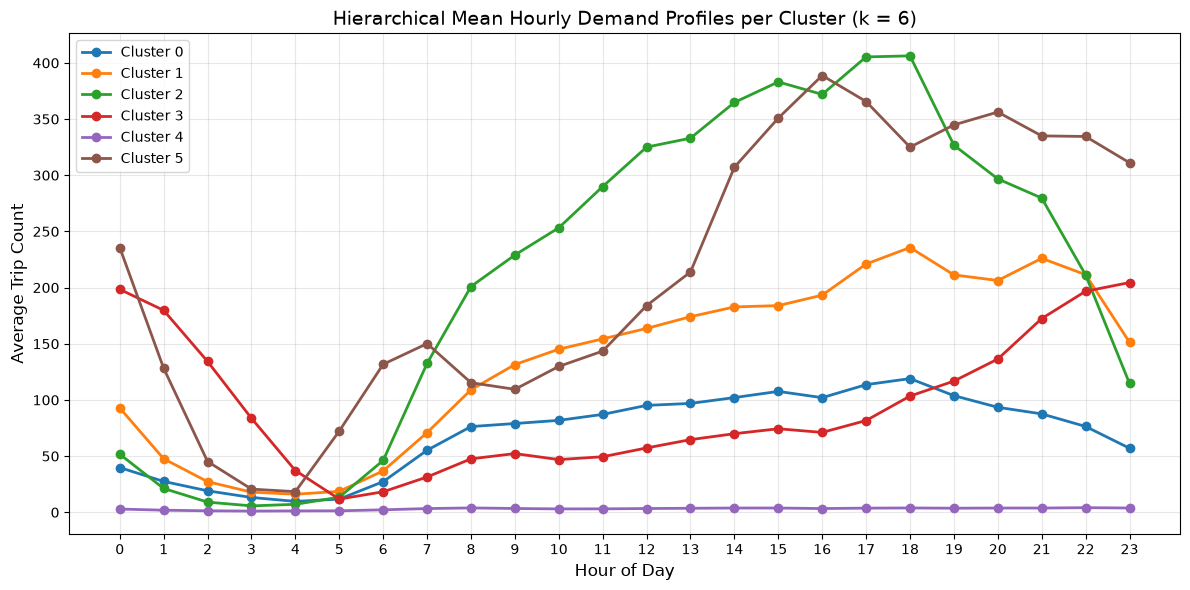

In [37]:
# 4. Plot Mean Hourly Demand Profiles for Hierarchical Clusters
cluster_profiles_hier = hier_profile_df.groupby("cluster").mean()

plt.figure(figsize=(12, 6))
for cluster_id in range(optimal_k):
  plt.plot(
      range(24),
      cluster_profiles_hier.loc[cluster_id, range(24)],
      marker="o",
      linewidth=2,
      label=f"Cluster {cluster_id}",
  )

plt.title(
    f"Hierarchical Mean Hourly Demand Profiles per Cluster (k = {optimal_k})",
    fontsize=14,
)
plt.xlabel("Hour of Day", fontsize=12)
plt.ylabel("Average Trip Count", fontsize=12)
plt.xticks(range(24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"../reports/figures/hierarchical_profiles_k{optimal_k}_seed_{current_random_state}.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [38]:
import pandas as pd

# 1. Load the official NYC TLC taxi zone lookup file
# (Adjusted to match your data path)
lookup_df = pd.read_csv("../data/spatial/taxi_zone_lookup.csv")

# 2. Extract zone metadata and merge with the lookup table for descriptive names
zone_meta = (
    train_df[["zone_id", "Borough", "service_zone"]]
    .drop_duplicates()
    .set_index("zone_id")
)

# Map the exact Zone names using LocationID as the key
zone_meta["Zone"] = lookup_df.set_index("LocationID")["Zone"]

# 3. Combine hierarchical cluster labels with zone metadata and average hourly demand
hier_cluster_summary_df = zone_meta.copy()
hier_cluster_summary_df["cluster"] = hier_profile_df["cluster"]
hier_cluster_summary_df["avg_hourly_trips"] = hier_profile_df[range(24)].mean(
    axis=1
)

# 4. Print a structured breakdown of the zones in each hierarchical cluster
for cluster_id in sorted(hier_cluster_summary_df["cluster"].unique()):
  subset = hier_cluster_summary_df[
      hier_cluster_summary_df["cluster"] == cluster_id
  ].sort_values(by="avg_hourly_trips", ascending=False)

  print(f"{'='*60}")
  print(
      f"HIERARCHICAL CLUSTER {cluster_id} | Total Zones: {len(subset)} | Mean"
      f" Demand: {subset['avg_hourly_trips'].mean():.1f} trips/hr"
  )
  print(f"Borough Breakdown: {subset['Borough'].value_counts().to_dict()}")
  print(f"{'-'*60}")

  # Display top 15 busiest zones including their neighborhood/zone names
  display(subset[["Zone", "Borough", "service_zone", "avg_hourly_trips"]].head(15))
  print("\n")

HIERARCHICAL CLUSTER 0 | Total Zones: 21 | Mean Demand: 70.1 trips/hr
Borough Breakdown: {'Manhattan': 21}
------------------------------------------------------------


,Zone,Borough,service_zone,avg_hourly_trips
zone_id,,,,
239,Upper West Side South,Manhattan,Yellow Zone,123.921209
141,Lenox Hill West,Manhattan,Yellow Zone,106.008302
140,Lenox Hill East,Manhattan,Yellow Zone,94.208177
246,West Chelsea/Hudson Yards,Manhattan,Yellow Zone,90.567982
263,Yorkville West,Manhattan,Yellow Zone,87.333020
238,Upper West Side North,Manhattan,Yellow Zone,87.303571
229,Sutton Place/Turtle Bay North,Manhattan,Yellow Zone,78.624843
90,Flatiron,Manhattan,Yellow Zone,77.105890
100,Garment District,Manhattan,Yellow Zone,71.007832




HIERARCHICAL CLUSTER 1 | Total Zones: 12 | Mean Demand: 134.5 trips/hr
Borough Breakdown: {'Manhattan': 11, 'Queens': 1}
------------------------------------------------------------


,Zone,Borough,service_zone,avg_hourly_trips
zone_id,,,,
186,Penn Station/Madison Sq West,Manhattan,Yellow Zone,163.617638
162,Midtown East,Manhattan,Yellow Zone,159.509555
230,Times Sq/Theatre District,Manhattan,Yellow Zone,159.279292
142,Lincoln Square East,Manhattan,Yellow Zone,141.394737
138,LaGuardia Airport,Queens,Airports,137.653822
170,Murray Hill,Manhattan,Yellow Zone,136.109179
234,Union Sq,Manhattan,Yellow Zone,135.337563
68,East Chelsea,Manhattan,Yellow Zone,130.377976
163,Midtown North,Manhattan,Yellow Zone,129.260808




HIERARCHICAL CLUSTER 2 | Total Zones: 3 | Mean Demand: 211.6 trips/hr
Borough Breakdown: {'Manhattan': 3}
------------------------------------------------------------


,Zone,Borough,service_zone,avg_hourly_trips
zone_id,,,,
161,Midtown Center,Manhattan,Yellow Zone,221.378289
237,Upper East Side South,Manhattan,Yellow Zone,220.788690
236,Upper East Side North,Manhattan,Yellow Zone,192.673872


... (2 outputs left out)



HIERARCHICAL CLUSTER 4 | Total Zones: 222 | Mean Demand: 3.1 trips/hr
Borough Breakdown: {'Queens': 67, 'Brooklyn': 61, 'Bronx': 43, 'Manhattan': 30, 'Staten Island': 20, 'EWR': 1}
------------------------------------------------------------


,Zone,Borough,service_zone,avg_hourly_trips
zone_id,,,,
87,Financial District North,Manhattan,Yellow Zone,34.034305
50,Clinton West,Manhattan,Yellow Zone,32.806548
13,Battery Park City,Manhattan,Yellow Zone,31.693296
166,Morningside Heights,Manhattan,Boro Zone,26.588816
125,Hudson Sq,Manhattan,Yellow Zone,25.568452
261,World Trade Center,Manhattan,Yellow Zone,25.402569
41,Central Harlem,Manhattan,Boro Zone,19.888001
74,East Harlem North,Manhattan,Boro Zone,18.210213
88,Financial District South,Manhattan,Yellow Zone,16.517074




HIERARCHICAL CLUSTER 5 | Total Zones: 1 | Mean Demand: 213.2 trips/hr
Borough Breakdown: {'Queens': 1}
------------------------------------------------------------


,Zone,Borough,service_zone,avg_hourly_trips
zone_id,,,,
132,JFK Airport,Queens,Airports,213.226034
